# 2.3 Re-checking my first notebook

This notebook belongs to step 2.3 of the extension, written up in `docs/report.md`, section 2.3. It reruns the data preparation, features and evaluation of my first notebook
through `rtm_forecast.reference`, which keeps that notebook's behaviour, and then changes one thing at a time. The test day is 19 January 2021 (96 blocks) and the models train on the 92 days before it.
The cross-validation result is read from `results/phase1_cv_comparison.json`, which `scripts/cv_comparison.py` writes (about 50 minutes, run once). Everything else runs in 3 to 6 minutes.
Prices are in INR/MWh. MAPE is the mean absolute percentage error.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

from rtm_forecast.ingest import load_raw
from rtm_forecast.reference import (
    RF_PARAMS,
    XGB_PARAMS,
    build_features,
    legacy_daily_mae,
    mae,
    mape,
    parse_dates,
    prepare_frame,
    quarter_mapes,
    split_last_day,
)

ROOT = Path("..").resolve()
FIG = ROOT / "docs" / "figures"
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
raw = load_raw(ROOT / "data" / "raw" / "price_data.csv")
frame = prepare_frame(raw)
split = split_last_day(build_features(frame))
actual = split.y_test
print(
    "test day mean price",
    round(actual.mean(), 4),
    "| train rows",
    len(split.y_train),
    "| test rows",
    len(actual),
)

test day mean price 3989.9465 | train rows 8832 | test rows 96


The training set has 8832 rows (92 days) and the test day has 96 rows. The mean price on the test day is 3989.9465.

In [2]:
# The 2021 results as saved in the notebook's export files
saved = {}
for name in ["RF", "XGB"]:
    table = pd.read_csv(ROOT / "original" / "results" / f"Forecast_{name}.csv")
    predicted = table["Actual RTM Price"].to_numpy() - table["Difference"].to_numpy()
    saved[name] = {
        "MAE": mae(actual, predicted),
        "MAPE": mape(actual, predicted),
        "accuracy (100 - MAPE)": 100 - mape(actual, predicted),
        "printed daily MAE": legacy_daily_mae(table["Difference"].to_numpy()),
    }
pd.DataFrame(saved).T.round(2)

,MAE,MAPE,accuracy (100 - MAPE),printed daily MAE
RF,708.77,15.32,84.68,707.45
XGB,757.87,16.17,83.83,756.53


These are my 2021 results, read from the saved forecast files. The first notebook called 100 minus MAPE the accuracy and wrote "about 85%". The files give 84.68 for the RandomForest and 83.83 for XGBoost.
The printed daily error (707.45 and 756.53) is slightly below the true mean absolute error (708.77 and 757.87).

In [3]:
# Simple forecasts for the same day, using no model at all
day = frame.iloc[-96:]
previous_day = frame["RTM_Price"].to_numpy()[-192:-96]
last_week = frame["RTM_Price"].to_numpy()[-672 - 96 : -672]
simple = {
    "same block yesterday": previous_day,
    "same block last week": last_week,
    "DAM price, same block": day["DAM_Price"].to_numpy(),
}
rows = {k: {"MAE": mae(actual, v), "MAPE": mape(actual, v)} for k, v in simple.items()}
baselines = pd.DataFrame(rows).T
baselines.round(2)

,MAE,MAPE
same block yesterday,431.57,10.98
same block last week,1088.43,21.83
"DAM price, same block",597.38,15.89


Three forecasts that use no model: yesterday's price in the same block, last week's price in the same block, and the DAM price. Yesterday's price has a MAPE of 10.98 and a MAE of 431.57.
Both 2021 models are worse on both measures (RF 15.32 and 708.77, XGBoost 16.17 and 757.87). The DAM price has a lower MAE than either model (597.38).

In [4]:
# Same models and parameters as in 2021, refit here (xgboost 3, scikit-learn 1). Only the inputs change between variants.
def fit_models(frame_variant, seeds=(0, 1, 2, 3, 4)):
    data = split_last_day(build_features(frame_variant))
    xgb = XGBRegressor(tree_method="exact", base_score=0.5, random_state=0, n_jobs=2, **XGB_PARAMS)
    xgb_pred = xgb.fit(data.x_train, data.y_train).predict(data.x_test)
    rf_preds = []
    for seed in seeds:
        rf = RandomForestRegressor(random_state=seed, n_jobs=2, **RF_PARAMS)
        rf_preds.append(rf.fit(data.x_train, data.y_train).predict(data.x_test))
    return xgb_pred, rf_preds


variants = {
    "as in 2021 (month-first dates, 6 holiday dates)": prepare_frame(raw),
    "day-first dates, same 6 holiday dates": prepare_frame(raw, dates="day_first"),
    "day-first dates, no holiday flag": prepare_frame(raw, dates="day_first", holidays=[]),
}
results = {}
for label, variant in variants.items():
    xgb_pred, rf_preds = fit_models(variant)
    results[label] = {"xgb": xgb_pred, "rf": rf_preds}
rows = []
for label, res in results.items():
    rf_mapes = [mape(actual, p) for p in res["rf"]]
    rows.append(
        {
            "variant": label,
            "XGB MAPE": mape(actual, res["xgb"]),
            "XGB MAE": mae(actual, res["xgb"]),
            "RF MAPE (mean of 5 seeds)": np.mean(rf_mapes),
            "RF MAPE min": min(rf_mapes),
            "RF MAPE max": max(rf_mapes),
            "RF MAE (mean of 5 seeds)": np.mean([mae(actual, p) for p in res["rf"]]),
        }
    )
table = pd.DataFrame(rows).set_index("variant")
table.round(2)

,XGB MAPE,XGB MAE,RF MAPE (mean of 5 seeds),RF MAPE min,RF MAPE max,RF MAE (mean of 5 seeds)
variant,,,,,,
"as in 2021 (month-first dates, 6 holiday dates)",16.17,757.87,15.37,15.28,15.47,711.96
"day-first dates, same 6 holiday dates",14.10,650.14,14.70,14.64,14.79,678.94
"day-first dates, no holiday flag",13.88,645.52,14.44,14.39,14.49,665.91


The same models with the same parameters as in 2021, refit here, with only the inputs changed. Reading the dates day-first lowers the XGBoost MAPE from 16.17 to 14.10 and the RandomForest MAPE (mean of five seeds) from 15.37 to 14.70.
Dropping the holiday flag as well lowers them to 13.88 and 14.44. One day cannot say whether the holiday flag really hurts, so I do not draw that conclusion. In every variant yesterday's price (10.98) is still better.

In [5]:
# Spread caused by the missing random seed alone, with the 2021 inputs
first = results["as in 2021 (month-first dates, 6 holiday dates)"]
print("RF MAPE by seed:", [round(mape(actual, p), 3) for p in first["rf"]])
print(
    "2021 saved:   RF MAPE",
    round(saved["RF"]["MAPE"], 3),
    "| XGB MAPE",
    round(saved["XGB"]["MAPE"], 3),
)
print("refit today:  XGB MAPE", round(mape(actual, first["xgb"]), 3))
print("quarters of the day, XGB refit:", [round(x, 2) for x in quarter_mapes(actual, first["xgb"])])

RF MAPE by seed: [15.47, 15.336, 15.275, 15.37, 15.4]
2021 saved:   RF MAPE 15.322 | XGB MAPE 16.171
refit today:  XGB MAPE 16.171
quarters of the day, XGB refit: [11.96, 22.5, 22.06, 8.17]


Without a seed the RandomForest result moves between 15.28 and 15.47 across five seeds. My 2021 result (15.32) sits inside that range. The XGBoost refit with a current library version gives 16.171 and the same four quarter-day errors as in 2021 (11.96, 22.50, 22.06 and 8.17), so the library upgrade did not change it.

In [6]:
# How many dates and weekend flags the month-first parse got wrong
unique = raw["Date"].drop_duplicates()
old, new = parse_dates(unique, "month_first"), parse_dates(unique, "day_first")
print("dates read differently:", int((old != new).sum()), "of", len(unique))
print(
    "days with a different Saturday/Sunday flag:",
    int(((old.dt.day_of_week >= 5) != (new.dt.day_of_week >= 5)).sum()),
)
holidays = pd.to_datetime(
    ["2020-10-02", "2020-10-25", "2020-10-30", "2020-11-14", "2020-12-25", "2020-12-31"]
)
print(
    "holiday dates that exist in the data under the 2021 parse:",
    [d.strftime("%d %b") for d in holidays if (old == d).any()],
)
print(
    "holiday dates that exist in the data when parsed correctly:",
    [d.strftime("%d %b") for d in holidays if (new == d).any()],
)

dates read differently: 44 of 111
days with a different Saturday/Sunday flag: 19
holiday dates that exist in the data under the 2021 parse: ['25 Oct', '30 Oct', '14 Nov', '25 Dec', '31 Dec']
holiday dates that exist in the data when parsed correctly: ['02 Oct', '25 Oct', '30 Oct', '14 Nov', '25 Dec', '31 Dec']


The month-first parse read 44 of the 111 dates wrongly. For example 01-10-2020 became 10 January. It gave 19 days the wrong Saturday/Sunday flag. Of the six holiday dates, five exist in the data under that parse. The sixth, 2 October, only exists when the dates are read correctly.
I check the holiday dates against an official list in step 2.4.

In [7]:
# The printed "mean absolute error of the day" against the true mean
for name in ["XGB", "RF"]:
    table_ = pd.read_csv(ROOT / "original" / "results" / f"Forecast_{name}.csv")
    diff = table_["Difference"].to_numpy()
    print(
        name,
        "printed:",
        round(legacy_daily_mae(diff), 2),
        "| true mean absolute error:",
        round(np.abs(diff).mean(), 2),
    )

XGB printed: 756.53 | true mean absolute error: 757.87
RF printed: 707.45 | true mean absolute error: 708.77


The loop behind the printed daily error never adds the last block's error, so the printed values are too low by 1.34 (XGBoost) and 1.32 (RandomForest).

In [8]:
# Cross-validation scheme (scripts/cv_comparison.py, about 6 minutes, run once)
cv = pd.DataFrame(json.loads((ROOT / "results" / "phase1_cv_comparison.json").read_text()))
cv[["scheme", "best_params", "cv_score_neg_mse", "test_day_mape", "test_day_mae"]]

,scheme,best_params,cv_score_neg_mse,test_day_mape,test_day_mae
0,"KFold(5), consecutive folds (notebook default)","{'colsample_bytree': 0.5, 'gamma': 0.05, 'lear...",-288694.97,16.171,757.87
1,"TimeSeriesSplit(5), forward chaining","{'colsample_bytree': 0.5, 'gamma': 0.05, 'lear...",-310720.03,15.617,730.07


The grid search in my first notebook used scikit-learn's default of five consecutive folds. In that scheme a training fold contains days that come after the validation days. Forward-chaining folds only train on the past.
The default scheme reproduces my 2021 winner (learning rate 0.07, score -288694.97, test-day MAPE 16.171). Forward chaining picks learning rate 0.06 with a worse score (-310720.03) and a better test-day MAPE (15.617).
The worse score is expected, because the early folds have little to train on. I do not read much into 15.62 against 16.17 on a single day.

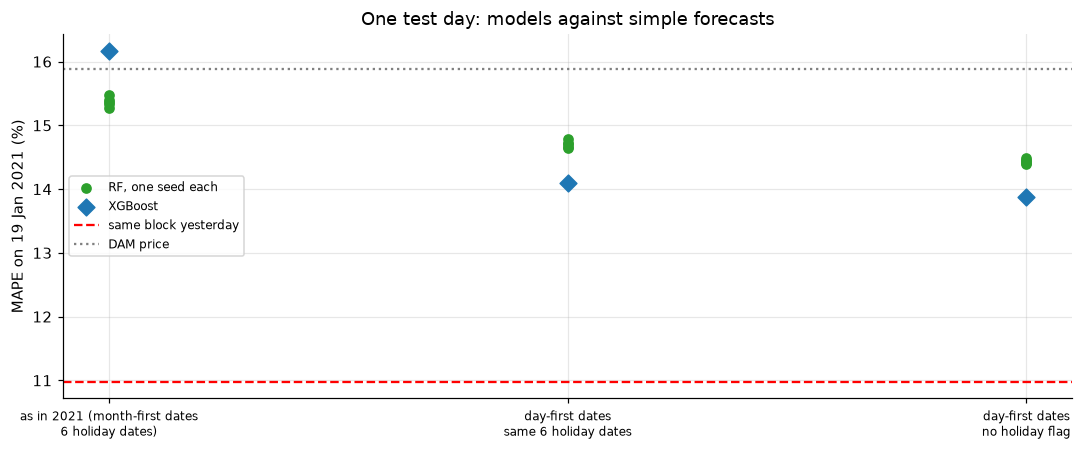

In [9]:
fig, ax = plt.subplots(figsize=(10, 4.2))
labels = list(results)
for i, label in enumerate(labels):
    res = results[label]
    ax.scatter(
        [i] * 5,
        [mape(actual, p) for p in res["rf"]],
        color="tab:green",
        label="RF, one seed each" if i == 0 else None,
        zorder=3,
    )
    ax.scatter(
        [i],
        [mape(actual, res["xgb"])],
        color="tab:blue",
        marker="D",
        s=60,
        label="XGBoost" if i == 0 else None,
        zorder=3,
    )
ax.axhline(
    baselines.loc["same block yesterday", "MAPE"],
    color="red",
    ls="--",
    label="same block yesterday",
)
ax.axhline(baselines.loc["DAM price, same block", "MAPE"], color="gray", ls=":", label="DAM price")
ax.set_xticks(range(len(labels)), [name.replace(", ", chr(10)) for name in labels], fontsize=8)
ax.set_ylabel("MAPE on 19 Jan 2021 (%)")
ax.set_title("One test day: models against simple forecasts")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "03_phase1_recheck.png")

**What I understand.** On this one day none of my models beat yesterday's price. Fixing the date parse changes the XGBoost error by about two points, which is more than the gap between the two models in 2021 (16.17 against 15.32).
One day cannot rank models: 19 January is the hardest day of the window (step 2.2). Steps 2.4 and 2.5 therefore fix the date handling, add the simple forecasts as baselines, and evaluate over many days.

## Rerunning the 2021 notebook itself

The cells above refit the models with current libraries. I also ran the original notebook cells unchanged in Python 3.8 with the library versions of February 2021 (`repro2020/`, see its README)
and compared every printed number with what the notebook printed in 2021 (`scripts/compare_reproduction.py`).

In [10]:
rec = json.loads((ROOT / "results" / "phase1_reproduction.json").read_text())
print(rec["summary"]["identical"], "of", rec["summary"]["items"], "printed values are identical")
pd.DataFrame(rec["summary"]["different"])[["cell", "what", "original", "rerun"]]

27 of 39 printed values are identical


,cell,what,original,rerun
0,86,Best Params,"Best Params: {'bootstrap': True, 'max_depth': ...","Best Params: {'bootstrap': True, 'max_depth': ..."
1,86,Best Score,Best Score: 0.5488524548371542,Best Score: 0.5490725803838947
2,88,Average Error,Average Error: 711.1415 degrees.,Average Error: 710.8982 degrees.
3,88,Accuracy,Accuracy = 84.64%.,Accuracy = 84.67%.
4,90,Maximum Error,Maximum Error of the day = 2598.4647404600973,Maximum Error of the day = 2639.4054007089776
5,90,Minimum Error,Minimum Error of the day = 15.490902050112709,Minimum Error of the day = 14.428759194326176
6,90,Mean Absolute Error,Mean Absolute Error of the day = [707.4508663...,Mean Absolute Error of the day = [715.1394070...
7,90,MAPE during 00:00,MAPE during 00:00-06:00 hrs = 12.912854536744248,MAPE during 00:00-06:00 hrs = 12.716392250408063
8,90,MAPE during 06:00,MAPE during 06:00-12:00 hrs = 21.037841105083967,MAPE during 06:00-12:00 hrs = 21.570789799009585
9,90,MAPE during 12:00,MAPE during 12:00-18:00 hrs = 17.95532627563596,MAPE during 12:00-18:00 hrs = 17.92329002366976


Everything printed by the data preparation cells and by the XGBoost grid search and evaluation is identical: the shapes, the missing-value counts, the day-type counts, the best parameters, the cross-validation score (-288694.97) and the test-day errors. The XGBoost forecasts are equal to the saved 2021 forecasts.
The 12 values that differ all belong to the RandomForest, which had no random seed. The grid picks the same parameters except `min_samples_split` (60 here, 36 in 2021), with a cross-validation R2 of 0.5491 against 0.5489. The test-day full-day MAPE is 15.418 here against 15.322 in 2021.
Cell 90 of the original calls a function that the notebook never defines, so its values come from a stand-in that I wrote to print the same lines. The XGBoost result is reproduced exactly. The RandomForest result is reproduced only approximately.